In [ ]:
!pip -q install wfdb scikit-learn

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

os.makedirs("results", exist_ok=True)
FS = 360
PRE, POST = 90, 162
SEG_LEN = PRE + POST

In [ ]:
record = wfdb.rdrecord("100", pn_dir="mitdb")
annotations = wfdb.rdann("100", "atr", pn_dir="mitdb")
signal = record.p_signal[:, 0]
print("Sampling frequency:", record.fs)
print("Channels:", record.sig_name)
print("Signal shape:", record.p_signal.shape)
print("Duration (minutes):", round(len(signal) / record.fs / 60, 2))
print("NaN count:", np.isnan(record.p_signal).sum())
print("Infinite count:", np.isinf(record.p_signal).sum())
for i, channel in enumerate(record.sig_name):
    x = record.p_signal[:, i]
    print(f"{channel}: min={x.min():.3f}, max={x.max():.3f}, mean={x.mean():.3f}, std={x.std():.3f}")

Sampling frequency: 360
Channels: ['MLII', 'V5']
Signal shape: (650000, 2)
Duration (minutes): 30.09
NaN count: 0
Infinite count: 0
MLII: min=-2.715, max=1.435, mean=-0.306, std=0.193
V5: min=-2.465, max=1.225, mean=-0.191, std=0.148


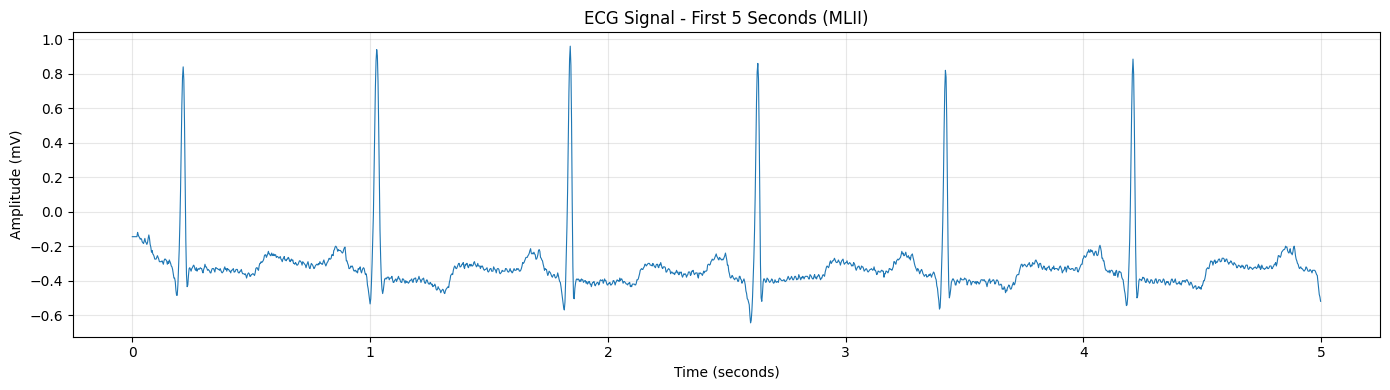

Saved: results/ecg_5_seconds.png


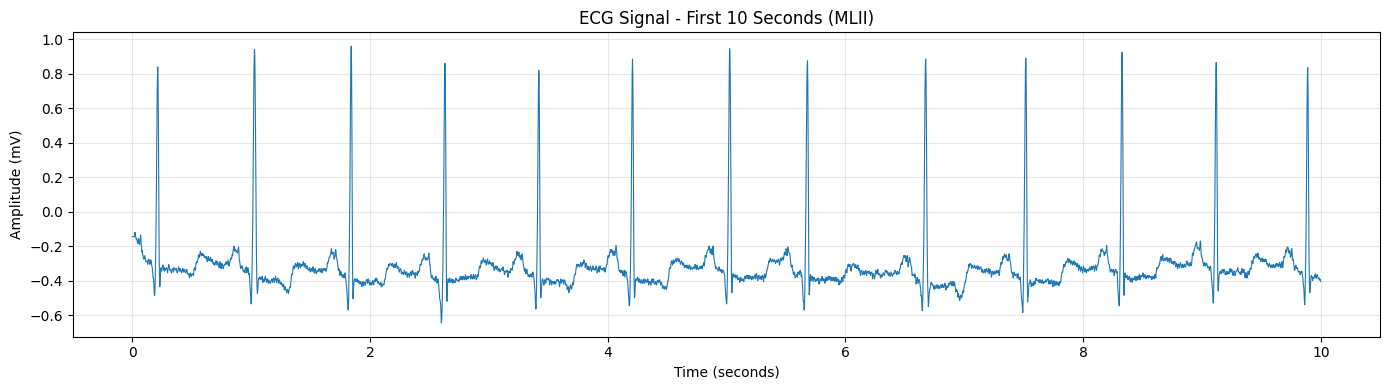

Saved: results/ecg_10_seconds.png


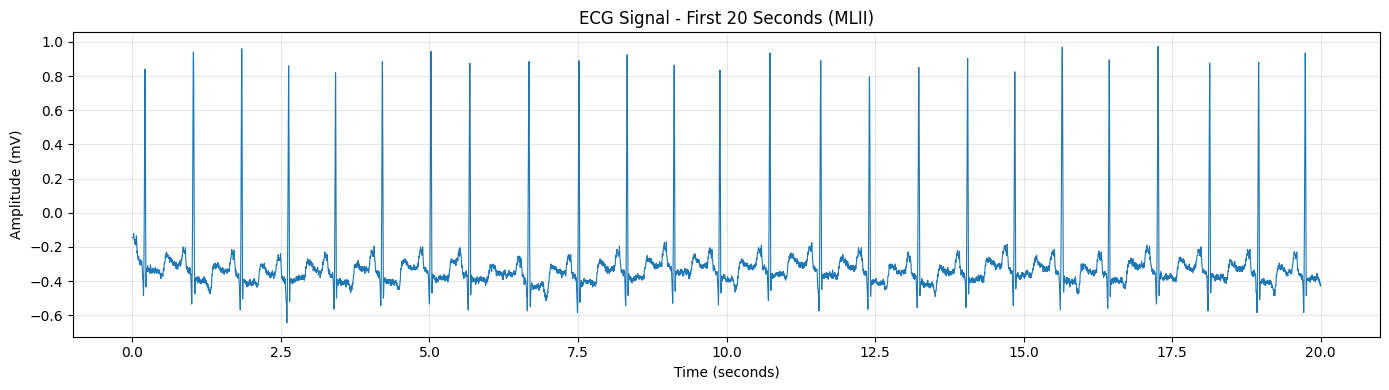

Saved: results/ecg_20_seconds.png


In [ ]:
for seconds in [5, 10, 20]:
    n = seconds * FS
    t = np.arange(n) / FS
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(t, signal[:n], linewidth=0.8)
    ax.set(title=f"ECG Signal - First {seconds} Seconds (MLII)",
           xlabel="Time (seconds)", ylabel="Amplitude (mV)")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    out = f"results/ecg_{seconds}_seconds.png"
    fig.savefig(out, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", out)

In [ ]:
TRAIN_RECORDS = ["100", "101", "103", "105", "108", "112",
                 "114", "116", "119", "200", "201", "203"]
TEST_RECORD = "106"
LABELS = {"N": 0, "A": 1, "V": 1}

def extract_segments(record_id):
    rec = wfdb.rdrecord(record_id, pn_dir="mitdb")
    ann = wfdb.rdann(record_id, "atr", pn_dir="mitdb")
    if rec.fs != FS:
        raise ValueError(f"Unexpected sampling rate for {record_id}: {rec.fs}")
    ecg = rec.p_signal[:, 0]
    X, y = [], []
    for sample, symbol in zip(ann.sample, ann.symbol):
        if symbol not in LABELS:
            continue
        start, end = int(sample) - PRE, int(sample) + POST
        if start < 0 or end > len(ecg):
            continue
        segment = ecg[start:end]
        if len(segment) == SEG_LEN and np.isfinite(segment).all():
            X.append(segment)
            y.append(LABELS[symbol])
    return np.asarray(X, dtype=float), np.asarray(y, dtype=int)

X_parts, y_parts, group_parts = [], [], []
for rid in TRAIN_RECORDS:
    print("Loading training record", rid, flush=True)
    Xr, yr = extract_segments(rid)
    X_parts.append(Xr)
    y_parts.append(yr)
    group_parts.extend([rid] * len(yr))

X_train = np.concatenate(X_parts)
y_train = np.concatenate(y_parts)
train_groups = np.asarray(group_parts)

print("Loading held-out test record", TEST_RECORD, flush=True)
X_test, y_test = extract_segments(TEST_RECORD)

print("\nTraining shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training values finite:", np.isfinite(X_train).all())
print("Test values finite:", np.isfinite(X_test).all())
print("\nTraining labels (0=normal, 1=abnormal):")
print(pd.Series(y_train).value_counts().sort_index())
print("\nTest labels (0=normal, 1=abnormal):")
print(pd.Series(y_test).value_counts().sort_index())

Loading training record 100
Loading training record 101
Loading training record 103
Loading training record 105
Loading training record 108
Loading training record 112
Loading training record 114
Loading training record 116
Loading training record 119
Loading training record 200
Loading training record 201
Loading training record 203
Loading held-out test record 106

Training shape: (26775, 252)
Test shape: (2027, 252)
Training values finite: True
Test values finite: True

Training labels (0=normal, 1=abnormal):
0    24537
1     2238
Name: count, dtype: int64

Test labels (0=normal, 1=abnormal):
0    1507
1     520
Name: count, dtype: int64


In [ ]:
rows = []
for rid in TRAIN_RECORDS:
    labels = y_train[train_groups == rid]
    rows.append({"record": rid, "segments": len(labels),
                 "normal": int((labels == 0).sum()),
                 "abnormal": int((labels == 1).sum())})
display(pd.DataFrame(rows))

,record,segments,normal,abnormal
0,100,2271,2237,34
1,101,1862,1859,3
2,103,2083,2081,2
3,105,2567,2526,41
4,108,1759,1738,21
5,112,2538,2536,2
6,114,1873,1820,53
7,116,2411,2301,110
8,119,1987,1543,444
9,200,2598,1742,856


In [ ]:
if len(np.unique(y_train)) < 2:
    raise ValueError("Training set must contain both classes.")

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=3000, random_state=42)
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Abnormal precision": precision_score(y_test, y_pred, zero_division=0),
    "Abnormal recall": recall_score(y_test, y_pred, zero_division=0),
    "Abnormal F1-score": f1_score(y_test, y_pred, zero_division=0)
}
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=["Normal", "Abnormal"], zero_division=0))

Accuracy: 0.9008
Abnormal precision: 0.9908
Abnormal recall: 0.6192
Abnormal F1-score: 0.7621

Classification report:
              precision    recall  f1-score   support

      Normal       0.88      1.00      0.94      1507
    Abnormal       0.99      0.62      0.76       520

    accuracy                           0.90      2027
   macro avg       0.94      0.81      0.85      2027
weighted avg       0.91      0.90      0.89      2027



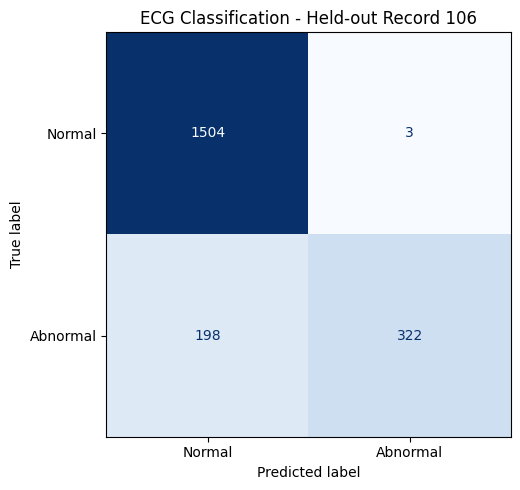

Saved: results/confusion_matrix_record_106.png


In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1],
    display_labels=["Normal", "Abnormal"], cmap="Blues",
    ax=ax, colorbar=False
)
ax.set_title(f"ECG Classification - Held-out Record {TEST_RECORD}")
fig.tight_layout()
cm_path = f"results/confusion_matrix_record_{TEST_RECORD}.png"
fig.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", cm_path)

In [ ]:
metrics_df = pd.DataFrame([{
    "test_record": TEST_RECORD,
    "training_records": ", ".join(TRAIN_RECORDS),
    **metrics
}])
metrics_df.to_csv("results/heldout_record_metrics.csv", index=False)
display(metrics_df)
print("Saved: results/heldout_record_metrics.csv")
print("Result files:", sorted(os.listdir("results")))

,test_record,training_records,Accuracy,Abnormal precision,Abnormal recall,Abnormal F1-score
0,106,"100, 101, 103, 105, 108, 112, 114, 116, 119, 2...",0.900839,0.990769,0.619231,0.76213


Saved: results/heldout_record_metrics.csv
Result files: ['confusion_matrix_record_106.png', 'ecg_10_seconds.png', 'ecg_20_seconds.png', 'ecg_5_seconds.png', 'heldout_record_metrics.csv']


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

print("Test samples:", len(y_test))
print("Predictions:", len(y_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Abnormal"],
    digits=4,
    zero_division=0
))

Test samples: 2027
Predictions: 2027

Confusion matrix:
[[1504    3]
 [ 198  322]]

Classification report:
              precision    recall  f1-score   support

      Normal     0.8837    0.9980    0.9374      1507
    Abnormal     0.9908    0.6192    0.7621       520

    accuracy                         0.9008      2027
   macro avg     0.9372    0.8086    0.8497      2027
weighted avg     0.9111    0.9008    0.8924      2027

